# Searching for an exomoon: detection with Pandora

This tutorial shows how to test a light curve for the signal of an exomoon with **Pandora**, from a raw light curve
to a verdict. It is written for first-time users: every step is explained.

**What you will do:**

1. Define a star, a planet and a moon (a Jupiter-like planet with a moon, around a Sun-like star).
2. Simulate a realistic light curve with stellar variability, red noise and exposure smearing.
3. Remove the stellar variability with `wotan` (detrending) and measure the noise.
4. Set up the likelihood and the priors.
5. Run Pandora's fast **detection test**, `pandoramoon.detect()`, and read its result.
6. Repeat it on two control light curves: the same planet **without** a moon, and a light curve without a moon but
   with an **artefact** in one transit, which can look like a moon.

Detection answers one question quickly (seconds per light curve): *is there evidence for a moon?* If yes, the next
step is the full fit, explained in the companion tutorial `tutorial_characterisation.ipynb`.

In [1]:
%matplotlib inline
import time as timer
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [12, 4]

import pandoramoon as pandora

## 1. The system: a star, a planet and a moon

Pandora describes a planet with a moon by 20 parameters. Their names and units are those of
`pandora.model_params()`. The planet and the moon orbit their common centre of mass, the *barycentre*: that is why
the planet's parameters are called `per_bary`, `a_bary`, ... . The moon makes the planet wobble around the
barycentre, so the planet's transits arrive slightly early or late (transit timing variations), and the moon adds
its own, small transit next to the planet's.

In [2]:
R_sun = 696_342_000  # [m]

def make_system(with_moon=True):
    params = pandora.model_params()
    # the star: like the Sun, with quadratic limb darkening u1, u2
    params.R_star = R_sun        # [m]
    params.u1 = 0.4089
    params.u2 = 0.2556
    # the planet: a Jupiter on a one-year orbit
    params.per_bary = 365.25     # orbital period of the planet-moon barycentre [days]
    params.a_bary = 215          # semi-major axis [stellar radii]; 215 R_sun = 1 AU
    params.r_planet = 0.1        # planet radius [stellar radii]; 0.1 R_sun = 1 Jupiter radius
    params.b_bary = 0.3          # impact parameter (0 = central transit)
    params.t0_bary = 11          # time of the first transit [days]
    params.t0_bary_offset = 0.01 # small shift of that time [days]
    params.M_planet = 1.8986e27  # [kg], 1 Jupiter mass
    params.w_bary = 0            # circular orbit
    params.ecc_bary = 0
    # the moon: about 3 Earth radii, 5-day orbit, 5 % of the planet's mass
    params.r_moon = 0.03 if with_moon else 1e-6    # [stellar radii]
    params.per_moon = 5          # [days]
    params.tau_moon = 0.07       # orbital phase of the moon at the first transit [0..1]
    params.Omega_moon = 0        # orientation of the moon's orbit [deg]
    params.i_moon = 90           # inclination of the moon's orbit [deg]; 90 = seen edge-on
    params.ecc_moon = 0
    params.w_moon = 0
    params.M_moon = (0.054 if with_moon else 1e-9) * params.M_planet   # [kg]
    # observing: 3 transits, 10 days of 30-min data around each
    params.epochs = 3
    params.epoch_duration = 10   # [days]
    params.cadences_per_day = 48 # 30-min cadence
    params.epoch_distance = 365.25
    params.occult_small_threshold = 0   # exact planet-moon overlaps
    params.hill_sphere_threshold = 1.0  # moons beyond the Hill sphere are not allowed
    return params

## 2. Simulate a realistic light curve

A real light curve is never just the transit. In this tutorial we build one that has the three things you will
meet in real data:

1. **Exposure smearing.** Kepler's long-cadence data points are averages over 29.4 minutes. A planet or moon
   transit changes during that time, so each data point is a time *average* of the true brightness. We compute the
   true light curve on a fine time grid (30 sub-exposures per data point, `supersampling_factor = 30`) and average
   it, exactly as the telescope does.
2. **Stellar variability.** Stars are not constant: spots rotating with the star make slow brightness changes of a
   few hundred ppm (parts per million) over days. We add two slow waves (periods 6.3 and 13.7 days).
3. **Noise.** Photon noise is *white* (independent from point to point, here 400 ppm per 30-min point). Stars and
   instruments also add *red* noise: small wiggles that last for hours, so neighbouring points are correlated. Red
   noise is the most common source of false moon signals, so we include it (120 ppm, correlated over ~3 hours).

We keep ±5 days of data around each of the three transits, as you would cut out of a long light curve.

In [3]:
def simulate_lightcurve(params, seed=1, white_noise=400e-6, red_noise=120e-6, artefact=None):
    """Simulated 30-min light curve of `params` (a pandora.model_params) with exposure smearing,
    stellar variability, white and red noise. artefact = (epoch, offset [d], depth, duration [d]):
    an extra box-shaped dip in one transit (to imitate an instrumental glitch)."""
    rng = np.random.default_rng(seed)
    # (1) the time stamps of the data points (one every 30 min), and the true flux averaged over each exposure
    params.supersampling_factor = 1
    time = pandora.time(params).grid()
    params.supersampling_factor = 30                     # 30 sub-exposures per data point
    flux_true, _, _ = pandora.moon_model(params).light_curve(pandora.time(params).grid())
    # (2) stellar variability: two slow waves (star spots)
    star = 1 + 400e-6 * np.sin(2 * np.pi * time / 6.3 + 1.0) + 600e-6 * np.sin(2 * np.pi * time / 13.7 + 2.0)
    # (3) red noise: random wiggles correlated over ~6 data points (3 hours) ...
    a = np.exp(-1 / 6.0)
    kick = rng.normal(0, 1, len(time))
    red = np.zeros(len(time))
    for i in range(1, len(time)):
        red[i] = a * red[i - 1] + np.sqrt(1 - a * a) * kick[i]
    # ... and white noise
    flux = flux_true * (star + red_noise * red) + rng.normal(0, white_noise, len(time))
    if artefact is not None:
        epoch, offset, depth, duration = artefact
        tc = params.t0_bary + params.t0_bary_offset + epoch * params.per_bary + offset
        box = 0.25 * (1 + np.tanh((time - tc + duration / 2) / 0.02)) * (1 - np.tanh((time - tc - duration / 2) / 0.02))
        flux = flux - depth * box
    return time, flux

1440 data points


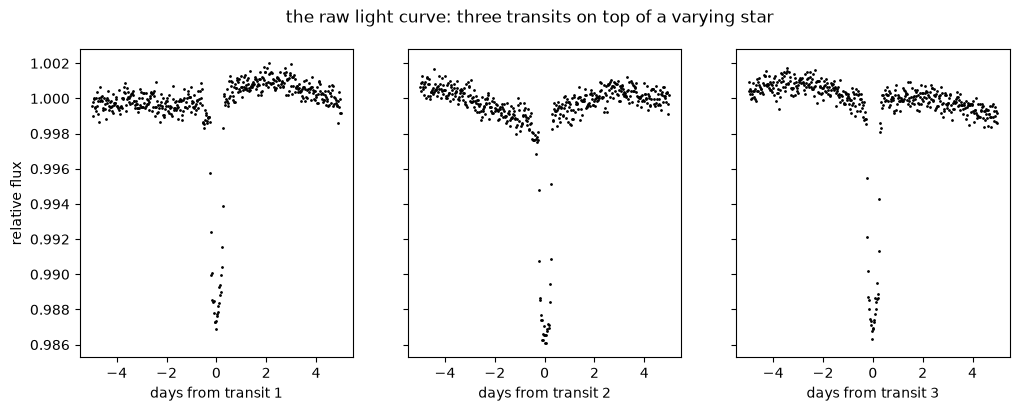

In [4]:
params = make_system(with_moon=True)
time, flux = simulate_lightcurve(params, seed=1)
print(len(time), "data points")

fig, axs = plt.subplots(1, 3, sharey=True)
for k, ax in enumerate(axs):
    tc = params.t0_bary + k * params.per_bary
    m = np.abs(time - tc) < 5
    ax.plot(time[m] - tc, flux[m], ".", ms=2, color="k")
    ax.set_xlabel(f"days from transit {k + 1}")
axs[0].set_ylabel("relative flux")
plt.suptitle("the raw light curve: three transits on top of a varying star")
plt.show()

The transits are the dips in the middle of each panel. The slow up-and-down is the star. The moon's own transit is
too small to see by eye here: it is the job of the fit to find it.

## 3. Remove the stellar variability (detrending)

Before fitting, we divide out the slow stellar variability. This is called *detrending*. We use `wotan` (Hippke et
al. 2019) through Pandora's helper `prepare_lightcurve`. It needs the planet's ephemeris (transit time `t0`,
period) and the transit duration T14. In a real search these come from a transit search (e.g. TLS or BLS); here
we compute T14 from the known orbit.

Two choices matter, and the helper uses the best values from our detrending study (300 injected planet+moon systems
in real Kepler light curves):

- **Mask = 1.0 × T14.** While the trend is estimated, the data within ±T14/2 of each transit are ignored, so the
  transit itself does not pull the trend down. A wider mask leaves the trend without data near the transit and adds
  noise; a narrower one lets the transit leak into the trend.
- **Window = 4.0 × T14.** The trend at each time is a robust average (`biweight`) over this window. Shorter windows
  follow the transit (and the moon) and remove part of the signal; longer windows cannot follow the star.
  4.0 × T14 is also robust when T14 is misestimated by −20 … +25 %.

The helper then keeps only the data near the transits (the *fit windows*, ±1.5 × T14 here) and measures the noise
from the detrended data *outside* those windows, where there is no signal:

- `sigma`: the white noise level (a robust standard deviation);
- `beta`: the **red-noise factor**: how much more the data scatter when averaged over T14/4 than white noise would.
  β = 1 is pure white noise; real Kepler stars have β ≈ 1.2–1.5. The error bars given to the fit are σ × β. This
  makes the fit honest about correlated wiggles: without it, red noise looks like a significant signal.

In [5]:
# the transit duration T14 (first to fourth contact) of a circular orbit
k_rp = params.r_planet
T14 = params.per_bary / np.pi * np.arcsin(np.sqrt((1 + k_rp) ** 2 - params.b_bary ** 2) / params.a_bary)
print(f"T14 = {T14:.3f} days = {24 * T14:.1f} hours")

t0 = params.t0_bary + params.t0_bary_offset    # in a real search: from TLS / BLS
lc = pandora.prepare_lightcurve(time, flux, t0=t0, period=params.per_bary, duration=T14)   # mask 1.0, window 4.0
print(f"white noise sigma = {1e6 * lc['sigma']:.0f} ppm, red-noise factor beta = {lc['beta']:.2f}, "
      f"error bars for the fit = {1e6 * lc['flux_err'][0]:.0f} ppm")
print(f"{len(lc['time'])} data points in the fit windows of transits {lc['epochs']}")

T14 = 0.572 days = 13.7 hours


white noise sigma = 413 ppm, red-noise factor beta = 1.18, error bars for the fit = 487 ppm
249 data points in the fit windows of transits [0, 1, 2]


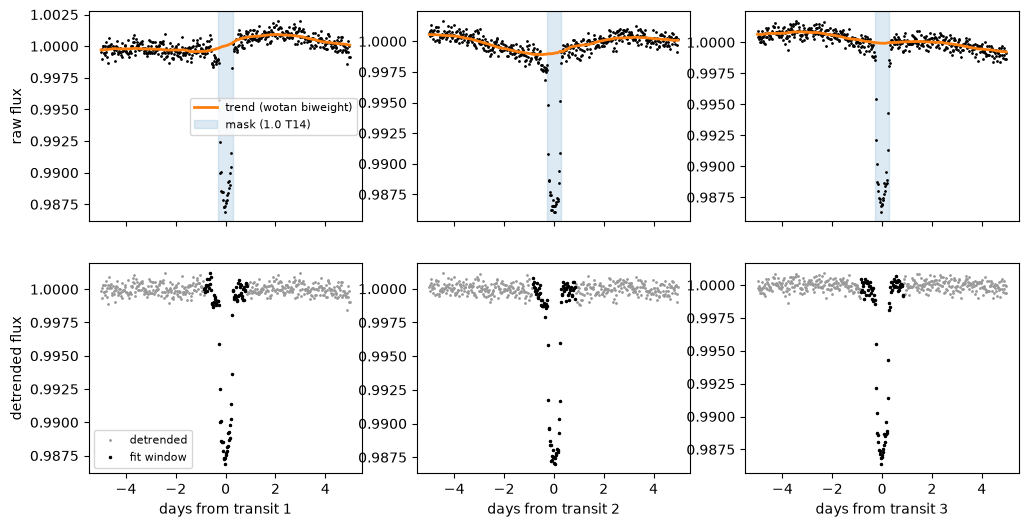

In [6]:
fig, axs = plt.subplots(2, 3, sharex="col", figsize=(12, 6))
for k in range(3):
    tc = t0 + k * params.per_bary
    m = np.abs(lc["time_all"] - tc) < 5
    x = lc["time_all"][m] - tc
    axs[0, k].plot(x, lc["flux_all"][m], ".", ms=2, color="k")
    axs[0, k].plot(x, lc["trend"][m], color="C1", lw=2, label="trend (wotan biweight)")
    axs[0, k].axvspan(-T14 / 2, T14 / 2, color="C0", alpha=0.15, label="mask (1.0 T14)")
    axs[1, k].plot(x, lc["flat"][m], ".", ms=2, color="0.6", label="detrended")
    w = m & lc["in_window"]
    axs[1, k].plot(lc["time_all"][w] - tc, lc["flat"][w], ".", ms=3, color="k", label="fit window")
    axs[1, k].set_xlabel(f"days from transit {k + 1}")
axs[0, 0].legend(fontsize=8); axs[1, 0].legend(fontsize=8)
axs[0, 0].set_ylabel("raw flux"); axs[1, 0].set_ylabel("detrended flux")
plt.show()

## 4. Likelihood and priors

**The likelihood** compares a model light curve with the data: for a given set of parameters it computes Pandora's
model at the times of the data and returns how well it fits (the log-likelihood, from χ² with the error bars). Pandora
evaluates it only near the transits, so it is fast (a few microseconds).

`epoch_distance` tells Pandora how far apart the transits are (the planet's period).

In [7]:
like = pandora.Likelihood(lc["time"], lc["flux"], lc["flux_err"], epoch_distance=params.per_bary,
                          hill_sphere_threshold=1.0)

**The priors** say which parameter values are possible *before* looking at the data. A moon search compares two
models:

- **planet only** (no moon), and
- **planet + moon**.

The evidence for a moon is the ratio of how well each model explains the data, *averaged over its priors*
(the Bayesian evidence Z). Its logarithm, **Δln Z = ln Z(planet + moon) − ln Z(planet only)**, is the Bayes factor.
A moon model can always fit a little better, because it has more freedom; the averaging over the priors penalises
that freedom (the *Occam penalty*). So the moon priors matter: they are part of the question.

`default_priors()` gives the priors that Pandora's detection threshold was calibrated with, scaled to your planet:
narrow priors around the known planet, and wide priors for the moon (any radius up to 0.7 planet radii, any orbital
period up to the limit of a stable orbit, any orientation, any mass up to half the planet's mass). You can change any
entry; then interpret Δln Z with care.

In [8]:
priors = pandora.default_priors(t0_bary=params.t0_bary, per_bary=params.per_bary, r_planet=0.1)
for name, prior in priors.items():
    print(f"{name:16s} {prior}")

q1               Uniform(lo=0.0, hi=1.0)
q2               Uniform(lo=0.0, hi=1.0)
R_star           Uniform(lo=557073600.0, hi=835610400.0)
per_bary         Uniform(lo=364.5195, hi=365.9805)
a_bary           LogUniform(lo=85.95973586976356, hi=537.2483491860223)
r_planet         Uniform(lo=0.05, hi=0.15000000000000002)
b_bary           Uniform(lo=0.0, hi=1.0)
t0_bary          11.0
t0_bary_offset   Uniform(lo=-0.05, hi=0.05)
M_planet         Uniform(lo=9.49065e+26, hi=2.847195e+27)
r_moon           Uniform(lo=0.010000000000000002, hi=0.06999999999999999)
per_moon         Uniform(lo=0.0, hi=69.397)
tau_moon         Uniform(lo=0.0, hi=1.0)
Omega_moon       Uniform(lo=0.0, hi=180.0)
i_moon           Uniform(lo=0.0, hi=180.0)
M_moon           Uniform(lo=0.0, hi=9.49065e+26)


## 5. The detection test

`pandora.detect()` runs a few short, fast fits of both models (a *first look*) and returns Δln Z. Its runs are independent
and run in parallel threads (one per run); it takes seconds (the very first call also compiles Pandora's code, ~20 s).

How to read the result:

- **`dlnz`**: the Bayes factor Δln Z. The first look is fast but noisy (about ±0.5).
- **`interesting`**: Δln Z > 3. This threshold was calibrated on thousands of simulated light curves: with these
  priors and honest error bars, light curves without a moon stay below it.
- **`jackknife`**: a real moon is seen in **several** transits. Pandora splits the fit improvement of the moon model
  by transit. If one transit carries almost all of it, the "moon" is more likely a glitch in that transit.
  `dchi2_without_top` is the improvement without the strongest transit; it must be ≥ 18.
- **`candidate`**: interesting **and** the jackknife passed. Only candidates deserve the full fit.
- **`moon`**: a rough first estimate of the moon (median and 68 % range).
- **`recall`** (an argument): how hard the test tries. `recall=0.95` (default) finds 95 % of clearly detectable moons;
  0.99 or 0.999 find more at 2–5× the cost.

In [9]:
t_start = timer.time()
det = pandora.detect(like, priors)
print(f"run time: {timer.time() - t_start:.1f} s (including compilation)")
print(f"Delta ln Z = {det['dlnz']:+.1f}   interesting: {det['interesting']}   candidate: {det['candidate']}")
print("fit improvement (Delta chi2) per transit:", np.round(det["jackknife"]["dchi2_epochs"], 1),
      f"-> without the strongest transit: {det['jackknife']['dchi2_without_top']:.1f}")
print("notes:", det["warnings"] or "none")
print()
truth = dict(per_moon=params.per_moon, r_moon=params.r_moon, i_moon=params.i_moon,
             **{"M_moon/M_planet": params.M_moon / params.M_planet})
for name, (median, lo, hi) in det["moon"].items():
    print(f"{name:16s} first look: {median:.4g}  (68 %: {lo:.4g} ... {hi:.4g})   true: {truth[name]:.4g}")

run time: 17.3 s (including compilation)
Delta ln Z = +78.6   interesting: True   candidate: True
fit improvement (Delta chi2) per transit: [63.7 77.  59.6] -> without the strongest transit: 123.3
notes: none

per_moon         first look: 5.141  (68 %: 4.74 ... 5.703)   true: 5
r_moon           first look: 0.0306  (68 %: 0.02956 ... 0.03154)   true: 0.03
i_moon           first look: 90.2  (68 %: 88.19 ... 92.13)   true: 90
M_moon/M_planet  first look: 0.03811  (68 %: 0.01898 ... 0.05996)   true: 0.054


The moon is clearly detected: Δln Z is far above 3 and all three transits contribute to it. The first-look moon
estimates are rough: the moon's radius and period are already close to the truth, but its mass (measured only
through the planet's small timing wobble) is poorly constrained by a fast test. The full fit gives reliable values
and uncertainties.

## 6. Controls: no moon, and an artefact

A test is only useful if it also says "no" when there is nothing. We apply it to two more light curves of the same
star:

1. **The same planet without a moon.**
2. **No moon, but an artefact**: a shallow, box-shaped dip of 1000 ppm lasting 11 hours, next to the planet's
   transit in **one** of the three transits. Such glitches happen in real data (spacecraft events, cosmic rays,
   stellar flares followed by dimming, imperfect detrending near data gaps). To a moon model, one dip next to a
   transit looks like a moon transit.

Both go through exactly the same steps.

In [10]:
def full_test(params, artefact=None, seed=1):
    time, flux = simulate_lightcurve(params, seed=seed, artefact=artefact)
    lc = pandora.prepare_lightcurve(time, flux, t0=t0, period=params.per_bary, duration=T14)
    like = pandora.Likelihood(lc["time"], lc["flux"], lc["flux_err"], epoch_distance=params.per_bary,
                              hill_sphere_threshold=1.0)
    return lc, like, pandora.detect(like, priors)

no_moon = make_system(with_moon=False)
lc_0, like_0, det_0 = full_test(no_moon)
lc_a, like_a, det_a = full_test(no_moon, artefact=(1, 0.38, 1000e-6, 0.45))   # in transit 2 (epoch 1)

for name, d in (("moon", det), ("no moon", det_0), ("no moon + artefact", det_a)):
    jk = d["jackknife"]
    print(f"{name:20s} Delta ln Z = {d['dlnz']:+6.1f}  interesting: {str(d['interesting']):5s}  "
          f"Delta chi2 without the strongest transit: {jk['dchi2_without_top']:6.1f}  candidate: {d['candidate']}")
print()
print("notes for the artefact case:", det_a["warnings"])

moon                 Delta ln Z =  +78.6  interesting: True   Delta chi2 without the strongest transit:  123.3  candidate: True
no moon              Delta ln Z =   -4.5  interesting: False  Delta chi2 without the strongest transit:    4.4  candidate: False
no moon + artefact   Delta ln Z =  +17.3  interesting: True   Delta chi2 without the strongest transit:    9.8  candidate: False

notes for the artefact case: ['dlnz 17.3 > threshold, but 86 % of the fit improvement comes from one transit (epoch 1): likely an artefact of that transit, not a moon']


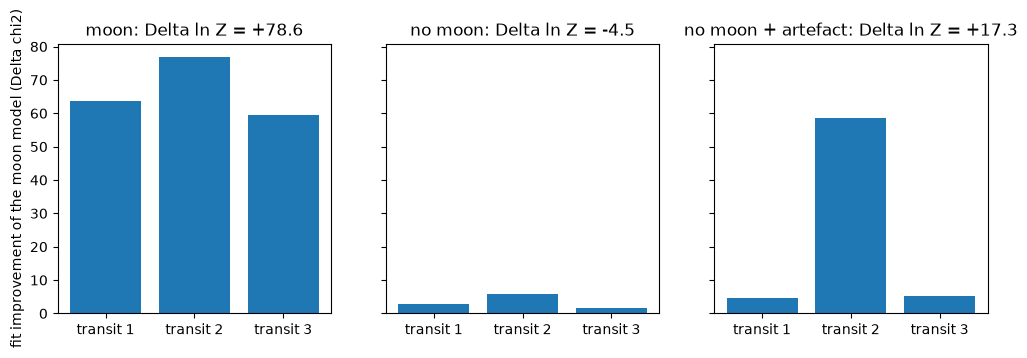

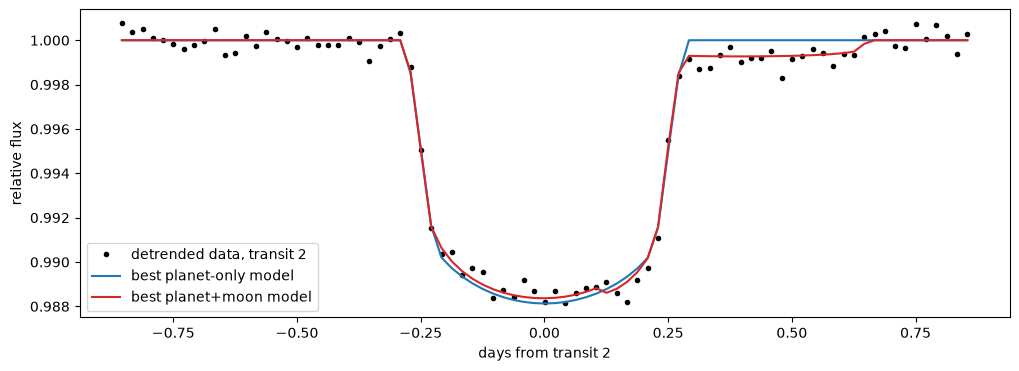

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (name, d) in zip(axs, (("moon", det), ("no moon", det_0), ("no moon + artefact", det_a))):
    jk = d["jackknife"]
    ax.bar([f"transit {e + 1}" for e in jk["epochs"]], jk["dchi2_epochs"], color="C0")
    ax.set_title(f"{name}: Delta ln Z = {d['dlnz']:+.1f}")
axs[0].set_ylabel("fit improvement of the moon model (Delta chi2)")
plt.show()

# the artefact transit, with the best moon fit of the first look
from pandoramoon.search import model_flux, cadence_times
tc = cadence_times(like_a)
e = 1
m = np.abs(tc - (t0 + e * params.per_bary)) < 1.0
plt.plot(tc[m] - t0 - e * params.per_bary, like_a.data[m], ".", color="k", label="detrended data, transit 2")
plt.plot(tc[m] - t0 - e * params.per_bary, model_flux(like_a, det_a["best"]["planet"])[m], color="C0", label="best planet-only model")
plt.plot(tc[m] - t0 - e * params.per_bary, model_flux(like_a, det_a["best"]["moon"])[m], color="C3", label="best planet+moon model")
plt.xlabel("days from transit 2"); plt.ylabel("relative flux"); plt.legend(); plt.show()

**What happened:**

- Without a moon, Δln Z is negative: the extra freedom of the moon model is not rewarded.
- With the artefact, Δln Z exceeds the threshold: by Δln Z alone this would be a "detection". The moon model fits the
  dip with a moon transit. But almost all of the improvement comes from transit 2. Without it, nothing remains, so
  the jackknife fails and `detect()` does **not** report a candidate, with a note explaining why.
- With the real moon, every transit contributes.

This check matters in practice: in our tests with real Kepler light curves, both false moon signals we found came
from a single bad transit.

## 7. Many light curves

`detect()` takes seconds, so it is suitable for searching many planets. Each call is independent; to use several
cores, run calls in parallel, e.g. with `concurrent.futures.ProcessPoolExecutor` (one light curve per process).

## Summary

| step | function | key settings |
|---|---|---|
| detrend, measure noise | `pandora.prepare_lightcurve(time, flux, t0, period, duration)` | mask 1.0 T14, window 4.0 T14 (defaults); error bars σ × β |
| likelihood | `pandora.Likelihood(time, flux, flux_err, epoch_distance=period)` | |
| priors | `pandora.default_priors(t0_bary, per_bary, r_planet)` | the calibrated moon priors |
| detection | `pandora.detect(like, priors)` | `recall=0.95`; candidate = Δln Z > 3 and the jackknife passed |

A candidate goes to the full fit: see `tutorial_characterisation.ipynb`.